# skillgraph in 10 minutes

Bayesian skill ratings (TrueSkill 1). Each cell shows one idea.

```bash
pip install git+https://github.com/Tahahaha7/skillgraph  pandas matplotlib
```

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, spearmanr

import skillgraph as sg
from skillgraph import TS1, Match, Rating

plt.style.use("seaborn-v0_8")
plt.rcParams.update({"figure.figsize": (10, 5), "axes.titlesize": 20, "axes.labelsize": 14,
                     "xtick.labelsize": 11, "ytick.labelsize": 11, "legend.fontsize": 12})
BLUE, ORANGE, RED, GREY = "#4C72B0", "#DD8452", "#C44E52", "#8C8C8C"

## 1. A rating is a bell curve, and a result makes it narrower

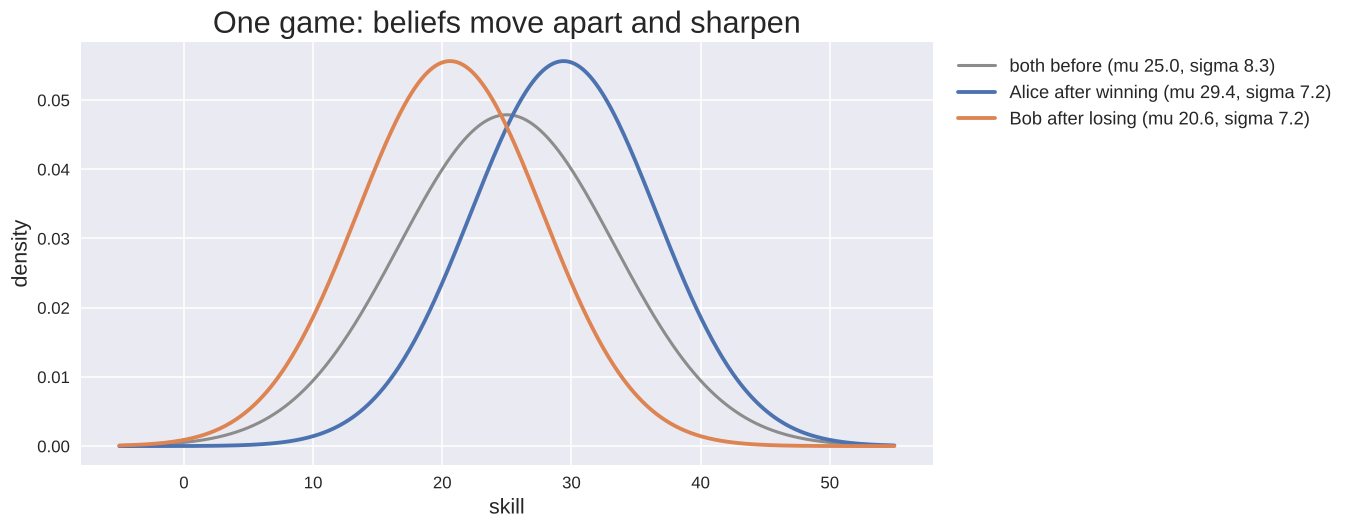

In [2]:
alice, bob = Rating(), Rating()                 # new players: mu=25, sigma=8.33
alice2, bob2 = sg.rate_1vs1(alice, bob)         # alice beat bob

x = np.linspace(-5, 55, 600)
plt.plot(x, norm.pdf(x, alice.mu, alice.sigma), color=GREY, lw=2, label="both before (mu 25.0, sigma 8.3)")
plt.plot(x, norm.pdf(x, alice2.mu, alice2.sigma), color=BLUE, lw=2.5, label=f"Alice after winning (mu {alice2.mu:.1f}, sigma {alice2.sigma:.1f})")
plt.plot(x, norm.pdf(x, bob2.mu, bob2.sigma), color=ORANGE, lw=2.5, label=f"Bob after losing (mu {bob2.mu:.1f}, sigma {bob2.sigma:.1f})")
plt.title("One game: beliefs move apart and sharpen")
plt.xlabel("skill"); plt.ylabel("density"); plt.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False);

## 2. Only surprises move ratings

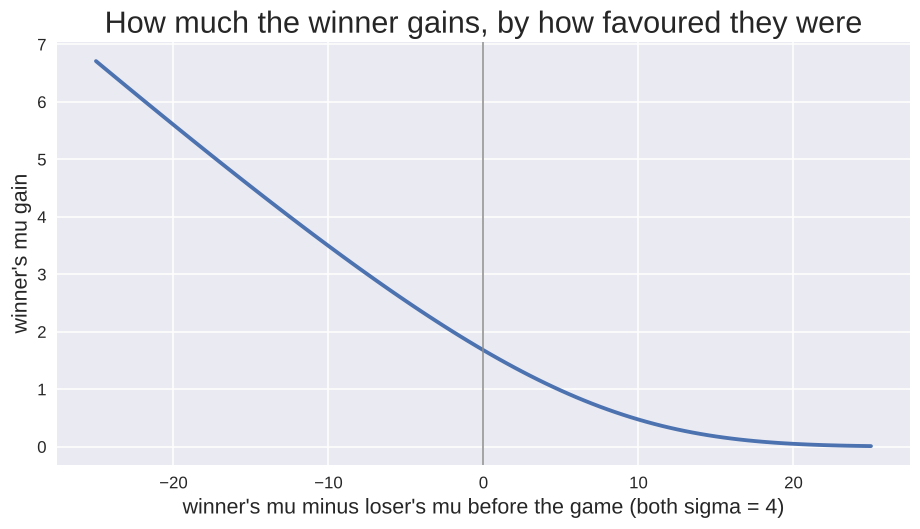

Text(31.072970920138903, 0.5, "winner's mu gain")

In [3]:
gaps = np.linspace(-25, 25, 101)
winner_change = [sg.rate_1vs1(Rating(25 + g / 2, 4), Rating(25 - g / 2, 4))[0].mu - (25 + g / 2) for g in gaps]

plt.plot(gaps, winner_change, color=BLUE, lw=2.5)
plt.axvline(0, color=GREY, lw=1)
plt.title("How much the winner gains, by how favoured they were")
plt.xlabel("winner's mu minus loser's mu before the game (both sigma = 4)")
plt.ylabel("winner's mu gain");

## 3. Any format: teams, uneven sides, free-for-alls, ties

In [4]:
formats = {
    "2v2, red won":             ([[Rating(28, 5), Rating(22, 7)], [Rating(25, 6), Rating(26, 4)]], [0, 1]),
    "1v2, the solo player won": ([[Rating()], [Rating(), Rating()]], [0, 1]),
    "4-way race, 2nd/3rd tied": ([[Rating(30, 4)], [Rating(25, 8)], [Rating(25, 8)], [Rating(20, 6)]], [0, 1, 1, 3]),
}
rows = []
for name, (teams, ranks) in formats.items():
    for t, (before, after) in enumerate(zip(teams, sg.rate(teams, ranks))):
        for b, a in zip(before, after):
            rows.append({"match": name, "team": t + 1, "rank": ranks[t], "mu before": b.mu, "mu after": a.mu,
                         "sigma before": b.sigma, "sigma after": a.sigma})
pd.DataFrame(rows).set_index(["match", "team"]).round(2)

rank  mu before  ...  sigma before  sigma after
match                    team                   ...                           
2v2, red won             1        0       28.0  ...          5.00         4.78
                         1        0       22.0  ...          7.00         6.39
                         2        1       25.0  ...          6.00         5.62
                         2        1       26.0  ...          4.00         3.89
1v2, the solo player won 1        0       25.0  ...          8.33         7.32
                         2        1       25.0  ...          8.33         7.32
                         2        1       25.0  ...          8.33         7.32
4-way race, 2nd/3rd tied 1        0       30.0  ...          4.00         3.70
                         2        1       25.0  ...          8.00         5.21
                         3        1       25.0  ...          8.00         5.21
                         4        3       20.0  ...          6.00         5.16

[11 rows x 5 columns]

## 4. A draw means more when draws are rare (`draw_probability`)

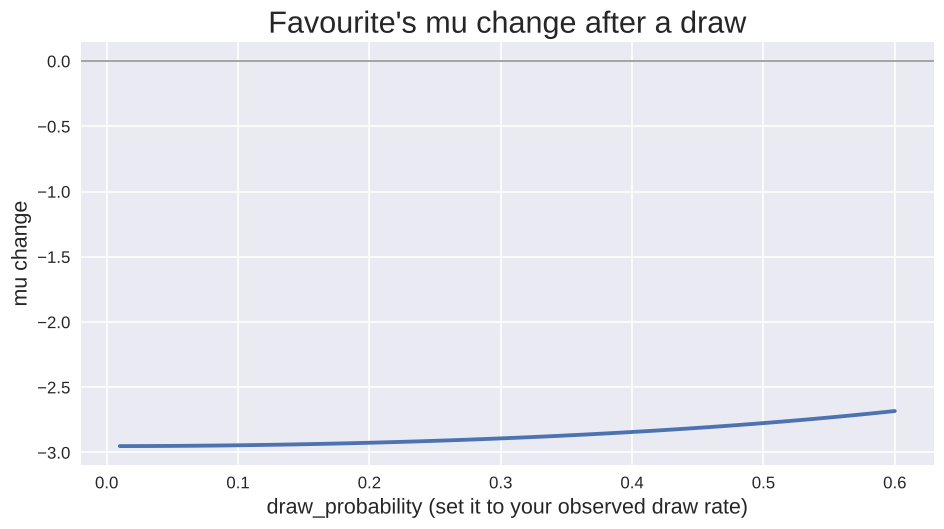

Text(31.072970920138903, 0.5, 'mu change')

In [5]:
fav, dog = Rating(30, 5), Rating(20, 5)
ps = np.linspace(0.01, 0.6, 50)
change = [TS1(draw_probability=p).rate_1vs1(fav, dog, drawn=True)[0].mu - fav.mu for p in ps]

plt.plot(ps, change, color=BLUE, lw=2.5)
plt.axhline(0, color=GREY, lw=1)
plt.title("Favourite's mu change after a draw")
plt.xlabel("draw_probability (set it to your observed draw rate)")
plt.ylabel("mu change");

## 5. Matchmaking: who gives the closest game?

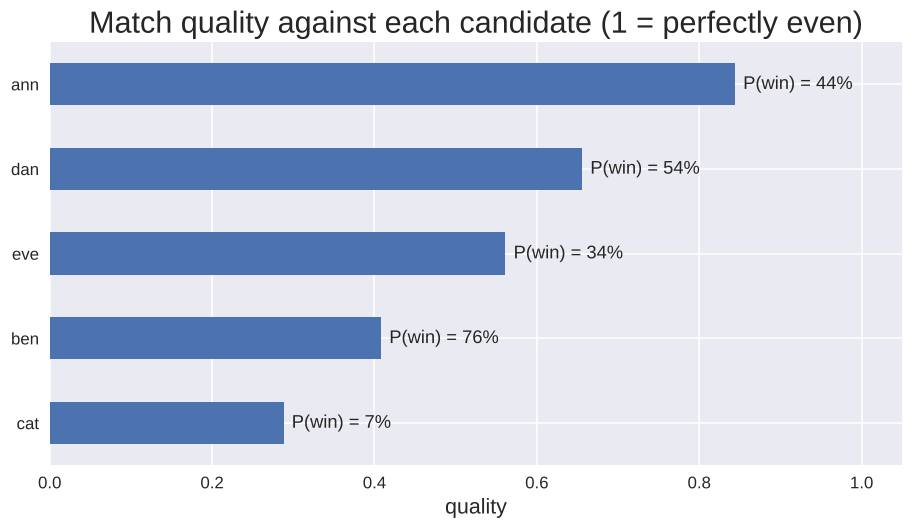

Text(0.5, 31.07297092013889, 'quality')

In [6]:
me = Rating(30, 3)
pool = {"ann": Rating(31, 2), "ben": Rating(22, 9), "cat": Rating(40, 1), "dan": Rating(29, 6), "eve": Rating(34, 7)}
table = pd.DataFrame({n: {"quality": sg.quality([[me], [r]]), "P(I win)": sg.win_probabilities([[me], [r]])[0]}
                      for n, r in pool.items()}).T.sort_values("quality")

ax = table["quality"].plot.barh(color=BLUE)
for i, (q, p) in enumerate(zip(table["quality"], table["P(I win)"])):
    ax.text(q + 0.01, i, f"P(win) = {p:.0%}", va="center", fontsize=12)
ax.set_xlim(0, 1.05); ax.set_title("Match quality against each candidate (1 = perfectly even)"); ax.set_xlabel("quality");

## 6. A simulated season: 200 players, 6,000 matches, four formats

In [7]:
rng = np.random.default_rng(7)
env = TS1(draw_probability=0.10)
n_players, n_matches = 200, 6000
truth = rng.normal(25, 25 / 3, n_players)

def result(teams):   # draw the outcome from the model: performance = skill + noise
    perf = [sum(truth[p] + rng.normal(0, env.beta) for p in t) for t in teams]
    order = np.argsort(perf)[::-1]
    ranks, r = [0] * len(teams), 0
    for a, b in zip(order, order[1:]):
        r += perf[a] - perf[b] > env.draw_margin(len(teams[a]) + len(teams[b]))
        ranks[b] = r
    return ranks

matches = []
for _ in range(n_matches):
    sizes = [[1, 1], [2, 2], [1, 2], [1, 1, 1, 1]][rng.integers(4)]
    ids = iter(rng.choice(n_players, size=sum(sizes), replace=False).tolist())
    teams = [[next(ids) for _ in range(s)] for s in sizes]
    matches.append(Match(teams, result(teams)))

t0 = time.time()
season = env.rate_matches(matches)
print(f"{n_matches} matches rated in {time.time() - t0:.1f} s")

6000 matches rated in 0.7 s


### How far off are the estimates?

Results only reveal skill *differences*, so the overall level stays anchored to the prior
(here the hidden mean happens to be 23.9, not 25). We compare after centring both.

hidden mean 23.9, estimated mean 24.7   |   90% of players within -1.40 .. +1.37 sigma of the truth


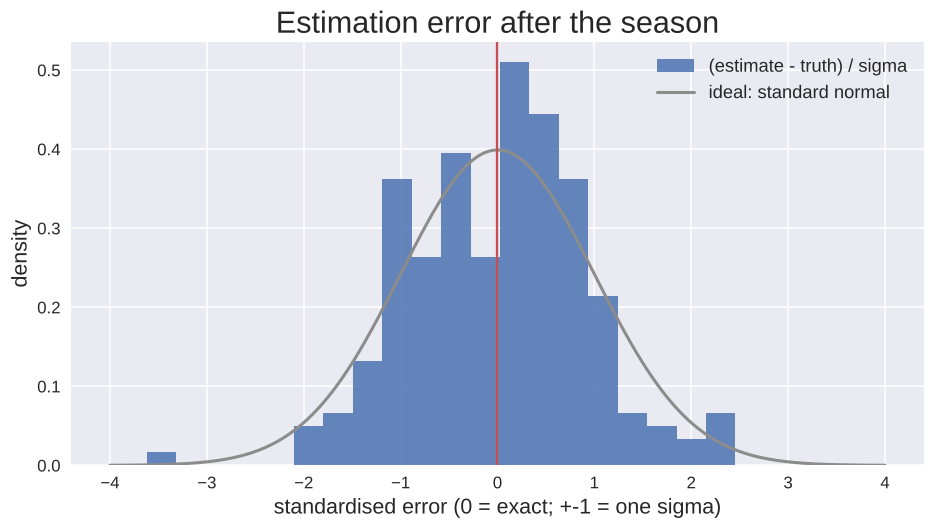

In [8]:
mu = np.array([season.ratings[p].mu for p in range(n_players)])
sigma = np.array([season.ratings[p].sigma for p in range(n_players)])
z = ((mu - mu.mean()) - (truth - truth.mean())) / sigma

lo5, hi95 = np.percentile(z, [5, 95])
print(f"hidden mean {truth.mean():.1f}, estimated mean {mu.mean():.1f}   |   90% of players within {lo5:+.2f} .. {hi95:+.2f} sigma of the truth")

plt.hist(z, bins=20, density=True, color=BLUE, alpha=0.85, label="(estimate - truth) / sigma")
zz = np.linspace(-4, 4, 300)
plt.plot(zz, norm.pdf(zz), color=GREY, lw=2, label="ideal: standard normal")
plt.axvline(z.mean(), color=RED, lw=1.5)
plt.title("Estimation error after the season")
plt.xlabel("standardised error (0 = exact; +-1 = one sigma)"); plt.ylabel("density"); plt.legend();

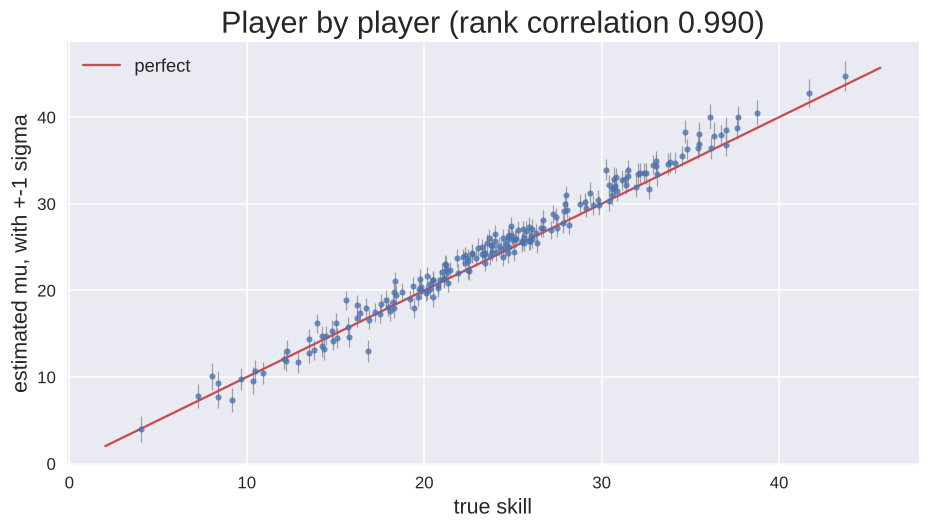

In [9]:
plt.errorbar(truth, mu, yerr=sigma, fmt="o", ms=4, color=BLUE, ecolor=GREY, elinewidth=0.8, alpha=0.8)
lo, hi = truth.min() - 2, truth.max() + 2
plt.plot([lo, hi], [lo, hi], color=RED, lw=1.5, label="perfect")
plt.title(f"Player by player (rank correlation {spearmanr(mu, truth).statistic:.3f})")
plt.xlabel("true skill"); plt.ylabel("estimated mu, with +-1 sigma"); plt.legend();

### Beliefs sharpen with every game

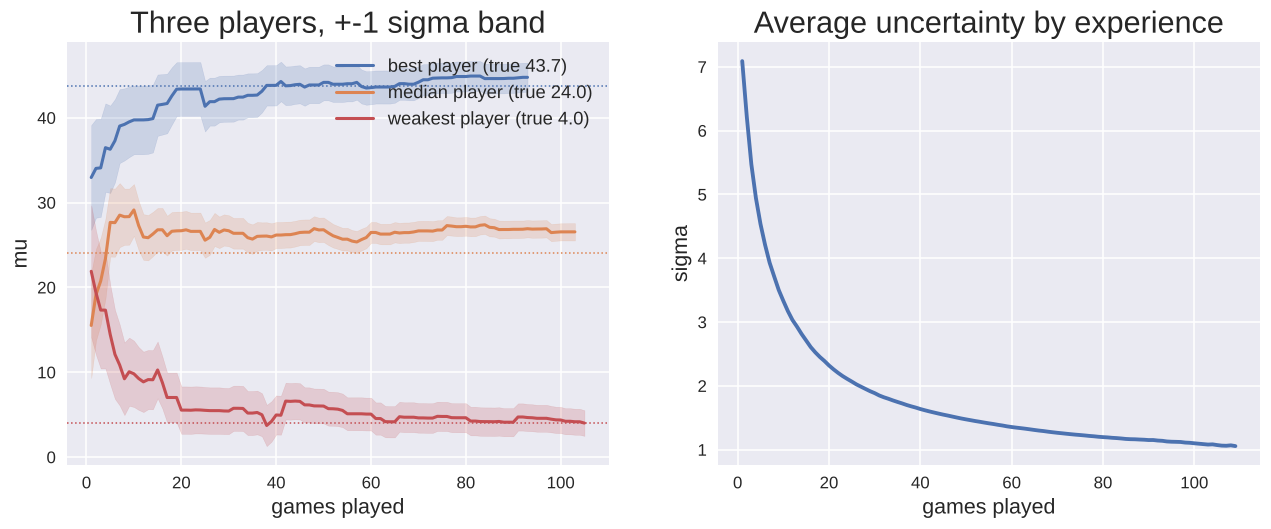

Text(691.4167209201388, 0.5, 'sigma')

In [10]:
tracked = {"best": int(np.argmax(truth)), "median": int(np.argsort(truth)[n_players // 2]), "weakest": int(np.argmin(truth))}
paths = {k: [] for k in tracked}
games = np.zeros(n_players, int)
sigma_at = {}
p_win, won = [], []

live = {}
for m in matches:
    teams = [[live.get(p, env.create_rating()) for p in t] for t in m.teams]
    if len(teams) == 2 and m.ranks[0] != m.ranks[1]:
        p_win.append(env.outcome_probability(teams, [0, 1])); won.append(m.ranks[0] < m.ranks[1])
    for ids, new in zip(m.teams, env.rate(teams, m.ranks)):
        for p, r in zip(ids, new):
            live[p] = r; games[p] += 1
            sigma_at.setdefault(games[p], []).append(r.sigma)
            for k, q in tracked.items():
                if p == q: paths[k].append((games[p], r.mu, r.sigma))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5))
for (k, path), c in zip(paths.items(), [BLUE, ORANGE, RED]):
    g, m_, s_ = map(np.array, zip(*path))
    a1.plot(g, m_, color=c, lw=2, label=f"{k} player (true {truth[tracked[k]]:.1f})")
    a1.fill_between(g, m_ - s_, m_ + s_, color=c, alpha=0.2)
    a1.axhline(truth[tracked[k]], color=c, lw=1, ls=":")
a1.set_title("Three players, +-1 sigma band"); a1.set_xlabel("games played"); a1.set_ylabel("mu"); a1.legend()
g = sorted(k for k in sigma_at if len(sigma_at[k]) >= 20)
a2.plot(g, [np.mean(sigma_at[k]) for k in g], color=BLUE, lw=2.5)
a2.set_title("Average uncertainty by experience"); a2.set_xlabel("games played"); a2.set_ylabel("sigma");

### The predictions are honest

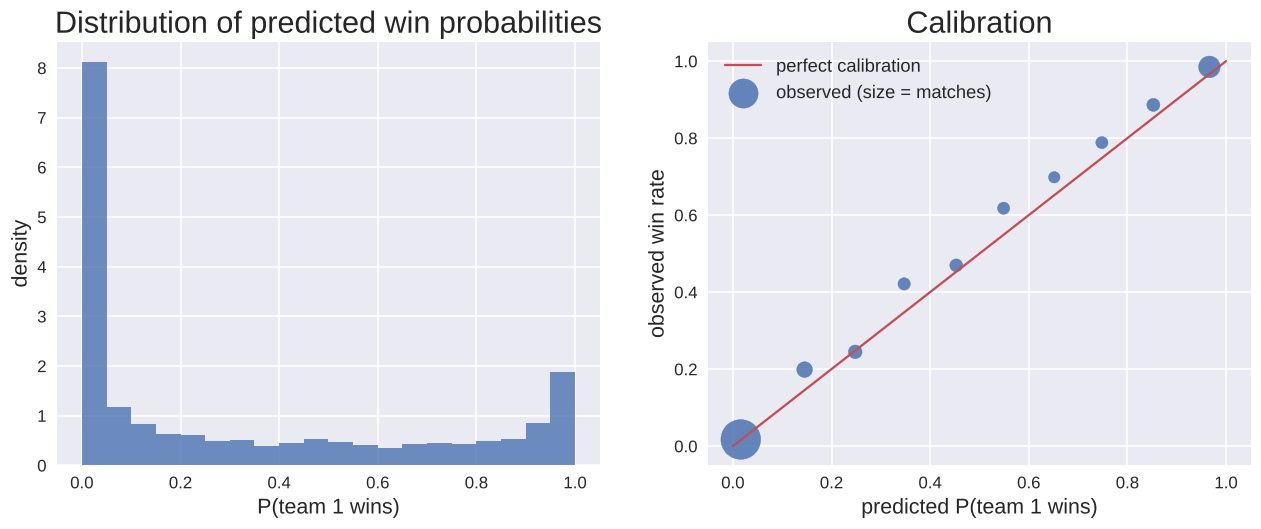

In [11]:
p_win, won = np.array(p_win), np.array(won, float)
edges = np.linspace(0, 1, 11)
mid, rate, n = [], [], []
for lo, hi in zip(edges[:-1], edges[1:]):
    sel = (p_win >= lo) & (p_win < hi)
    if sel.sum() >= 30:
        mid.append(p_win[sel].mean()); rate.append(won[sel].mean()); n.append(sel.sum())

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5))
a1.hist(p_win, bins=20, density=True, color=BLUE, alpha=0.8)
a1.set_title("Distribution of predicted win probabilities"); a1.set_xlabel("P(team 1 wins)"); a1.set_ylabel("density")
a2.plot([0, 1], [0, 1], color=RED, lw=1.5, label="perfect calibration")
a2.scatter(mid, rate, s=np.array(n) / 3, color=BLUE, alpha=0.85, label="observed (size = matches)")
a2.set_title("Calibration"); a2.set_xlabel("predicted P(team 1 wins)"); a2.set_ylabel("observed win rate"); a2.legend();

## 7. Pick settings with data: log-loss on the actual results

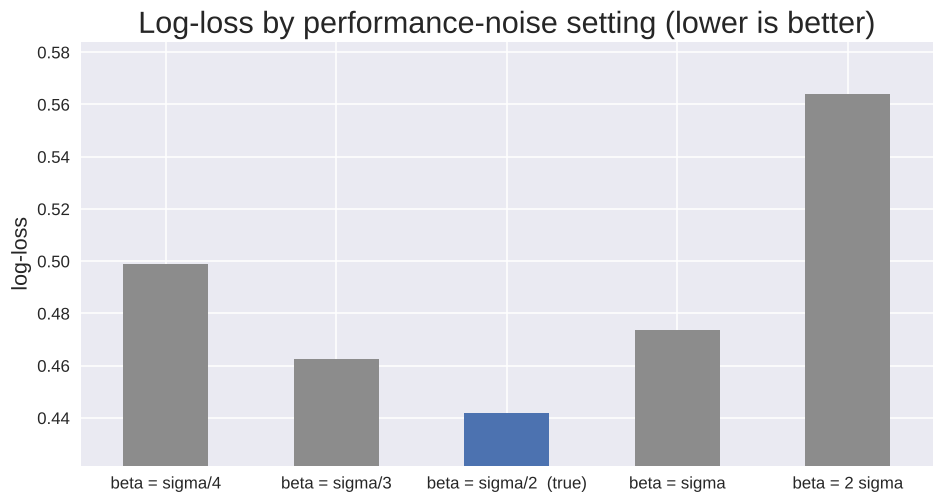

Text(31.072970920138903, 0.5, 'log-loss')

In [12]:
two_team = [m for m in matches if len(m.teams) == 2]
scores = {}
for label, beta in [("sigma/4", 25 / 12), ("sigma/3", 25 / 9), ("sigma/2  (true)", 25 / 6), ("sigma", 25 / 3), ("2 sigma", 50 / 3)]:
    res = TS1(beta=beta, draw_probability=0.10).rate_matches(two_team, with_probabilities=True)
    scores[f"beta = {label}"] = -np.mean(np.log(res.probabilities))

ax = pd.Series(scores).plot.bar(color=[GREY, GREY, BLUE, GREY, GREY], rot=0)
ax.set_ylim(min(scores.values()) - 0.02, max(scores.values()) + 0.02)
ax.set_title("Log-loss by performance-noise setting (lower is better)"); ax.set_ylabel("log-loss");

## 8. It does not fall over

In [13]:
print("million-sigma upset:", sg.rate_1vs1(Rating(0, 1), Rating(1e6, 1)))

big = [[Rating(float(m), 3.0)] for m in rng.normal(25, 8, 500)]
t0 = time.time(); out = sg.rate(big)
print(f"500-player free-for-all: {1000 * (time.time() - t0):.0f} ms")

a, b = Rating(), Rating(30, 4)
t0 = time.time()
for _ in range(20000):
    sg.rate_1vs1(a, b)
print(f"1v1 updates per second: {20000 / (time.time() - t0):,.0f}")

million-sigma upset: (Rating(mu=27410.228, sigma=0.990), Rating(mu=972589.772, sigma=0.990))
500-player free-for-all: 179 ms
1v1 updates per second: 90,706


More: `docs/ts1.md` (accuracy, fixes, limitations), `ROADMAP.md` (TrueSkill 2, real-data evaluation).